# Pipeline de Ciência de Dados — Heart Failure Prediction

**Integrantes:** Pedro Lucas Francisco, Nathalia Rodrigues e Pedro Henrique Cavalcante

Objetivo: prever a presença de doença cardíaca (`HeartDisease`) a partir de dados clínicos.

## Índice

0. Bibliotecas e configuração
1. Dados
2. Pré-processamento
3. Engenharia de atributos
4. Construção do pipeline
5. Redução de dimensionalidade (Rank e PCA)
6. Modelos e métricas
7. Otimização de hiperparâmetros
8. Exportação do modelo para produção
9. Conclusão

## Como executar

Na raiz do projeto, com as dependências de `requirements.txt` instaladas, abra este notebook (ele precisa rodar
a partir da pasta `notebooks/`) e execute as células em ordem. Ao final ele grava o modelo em `models/`
e as figuras em `relatorio/figuras/`.

## Dicionário de dados

| Atributo | Tipo | Significado |
|---|---|---|
| `Age` | número | idade em anos |
| `Sex` | categoria | sexo (M ou F) |
| `ChestPainType` | categoria | tipo de dor no peito (TA, ATA, NAP, ASY) |
| `RestingBP` | número | pressão arterial em repouso (mm Hg) |
| `Cholesterol` | número | colesterol sérico (mg/dl) |
| `FastingBS` | 0 ou 1 | glicemia em jejum acima de 120 mg/dl |
| `RestingECG` | categoria | eletrocardiograma em repouso (Normal, ST, LVH) |
| `MaxHR` | número | frequência cardíaca máxima atingida |
| `ExerciseAngina` | categoria | angina induzida por exercício (Y ou N) |
| `Oldpeak` | número | depressão do segmento ST no exercício |
| `ST_Slope` | categoria | inclinação do segmento ST (Up, Flat, Down) |
| `HeartDisease` | 0 ou 1 | **alvo**: 1 indica doença cardíaca |

## 0. Bibliotecas e configuração

In [1]:
import sys, os, json, warnings, functools

# O módulo src.features fica na raiz do projeto, um nível acima da pasta do notebook.
sys.path.append(os.path.abspath(".."))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import sklearn, joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)

from src.features import preparar, NUMERICAS, CATEGORICAS, COLUNAS_ENTRADA

SEMENTE_ALEATORIA = 42   # fixa a aleatoriedade para os resultados serem reproduzíveis
PASTA_FIGURAS = "../relatorio/figuras"
PASTA_MODELOS = "../models"
sns.set_theme(style="whitegrid")
os.makedirs(PASTA_FIGURAS, exist_ok=True)
os.makedirs(PASTA_MODELOS, exist_ok=True)


def salvar_figura(nome_arquivo):
    """Salva a figura atual em alta resolução para ser usada no relatório."""
    plt.savefig(f"{PASTA_FIGURAS}/{nome_arquivo}.png", dpi=150, bbox_inches="tight")


def calcular_metricas(pipeline_treinado, atributos_teste, alvo_teste):
    """Calcula as cinco métricas de classificação usadas para comparar os modelos."""
    classe_prevista = pipeline_treinado.predict(atributos_teste)
    probabilidade_doenca = pipeline_treinado.predict_proba(atributos_teste)[:, 1]
    return {
        "accuracy": accuracy_score(alvo_teste, classe_prevista),
        "precision": precision_score(alvo_teste, classe_prevista),
        "recall": recall_score(alvo_teste, classe_prevista),
        "f1": f1_score(alvo_teste, classe_prevista),
        "roc_auc": roc_auc_score(alvo_teste, probabilidade_doenca),
    }


# Versões das bibliotecas, registradas para a seção "Material e Métodos" do relatório.
versoes_bibliotecas = pd.DataFrame({
    "biblioteca": ["python", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "joblib"],
    "versao": [sys.version.split()[0], pd.__version__, np.__version__, sklearn.__version__,
               plt.matplotlib.__version__, sns.__version__, joblib.__version__],
})
versoes_bibliotecas

,biblioteca,versao
0,python,3.12.10
1,pandas,3.1.1
2,numpy,2.5.5
3,scikit-learn,1.9.1
4,matplotlib,3.11.2
5,seaborn,0.13.2
6,joblib,1.6.0


## 1. Dados

In [2]:
dados = pd.read_csv("../data/heart.csv")
print("Formato:", dados.shape)
dados.head()

Formato: (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
print(dados.dtypes)
print("\nDuplicatas:", dados.duplicated().sum())
# Zero é fisiologicamente impossível nessas duas colunas: indica medida não realizada.
print("Cholesterol == 0:", (dados["Cholesterol"] == 0).sum(), "| RestingBP == 0:", (dados["RestingBP"] == 0).sum())
print("\nBalanceamento do alvo:")
print(dados["HeartDisease"].value_counts(normalize=True).round(3))
dados.describe().T

Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

Duplicatas: 0
Cholesterol == 0: 172 | RestingBP == 0: 1

Balanceamento do alvo:
HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64


,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


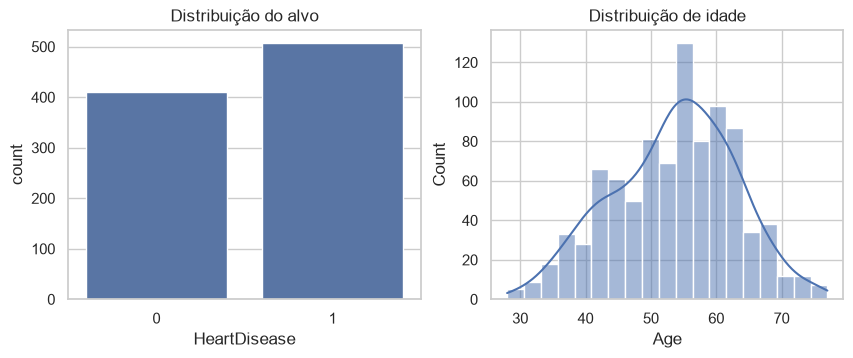

In [4]:
figura, eixos = plt.subplots(1, 2, figsize=(10, 3.5))
sns.countplot(x="HeartDisease", data=dados, ax=eixos[0]); eixos[0].set_title("Distribuição do alvo")
sns.histplot(dados["Age"], kde=True, ax=eixos[1]); eixos[1].set_title("Distribuição de idade")
salvar_figura("01_distribuicao_alvo_idade")
plt.show()

**Leitura:** cerca de 55% dos pacientes têm doença cardíaca, então as classes são razoavelmente balanceadas e dispensam
técnicas de reamostragem. As 172 medidas de colesterol iguais a 0 serão tratadas como ausentes na próxima etapa.
Esses valores ausentes não são aleatórios: eles se concentram nos pacientes doentes (cerca de 30%, contra 5% nos saudáveis).

## 2. Pré-processamento

- Remoção de registros duplicados.
- Valores `0` em `Cholesterol` e `RestingBP` são fisiologicamente impossíveis: tratados como ausentes
  (função `preparar`, em `src/features.py`).
- Imputação pela **mediana**, padronização (`StandardScaler`) das numéricas e `OneHotEncoder` das categóricas.
- Todas essas etapas ficam **dentro do Pipeline** e são ajustadas só com os dados de treino, evitando vazamento de dados.
- Divisão treino/teste 80/20, estratificada pelo alvo.

In [5]:
dados = dados.drop_duplicates().reset_index(drop=True)
atributos = dados[COLUNAS_ENTRADA]
alvo = dados["HeartDisease"]

# Estratificar mantém a proporção de doentes igual no treino e no teste.
atributos_treino, atributos_teste, alvo_treino, alvo_teste = train_test_split(
    atributos, alvo, test_size=0.2, stratify=alvo, random_state=SEMENTE_ALEATORIA)
print("Treino:", atributos_treino.shape, "| Teste:", atributos_teste.shape)
print("Ausentes após tratar zeros:")
print(preparar(atributos_treino).isna().sum()[lambda contagem: contagem > 0])

Treino: (734, 11) | Teste: (184, 11)
Ausentes após tratar zeros:
Cholesterol    129
dtype: int64


## 3. Engenharia de atributos

Três atributos novos, criados em `preparar`:

| Atributo | Descrição |
|---|---|
| `FaixaEtaria` | faixa etária (até 40, 41–50, 51–60, acima de 60) |
| `MaxHR_pct` | frequência cardíaca máxima atingida / FC máxima teórica (220 − idade) |
| `ColesterolAlto` | 1 se colesterol ≥ 240 mg/dl, senão 0 |

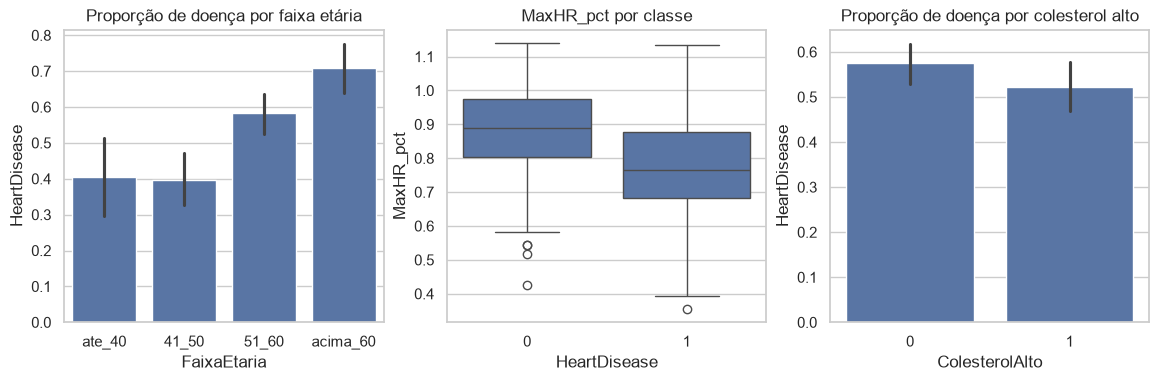

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,FaixaEtaria,MaxHR_pct,ColesterolAlto,HeartDisease
485,63,M,ATA,139,217.0,1,ST,128,Y,1.2,Flat,acima_60,0.815287,0,1
486,55,M,ATA,110,214.0,1,ST,180,N,0.4,Up,51_60,1.090909,0,0
117,59,F,ASY,130,338.0,1,ST,130,Y,1.5,Flat,51_60,0.807453,1,1
361,47,M,ASY,160,NaN,0,Normal,124,Y,0.0,Flat,41_50,0.716763,0,1
296,50,M,ASY,145,NaN,1,Normal,139,Y,0.7,Flat,41_50,0.817647,0,1


In [6]:
treino_com_novos_atributos = preparar(atributos_treino).assign(HeartDisease=alvo_treino.values)
figura, eixos = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(x="FaixaEtaria", y="HeartDisease", data=treino_com_novos_atributos,
            order=["ate_40", "41_50", "51_60", "acima_60"], ax=eixos[0])
sns.boxplot(x="HeartDisease", y="MaxHR_pct", data=treino_com_novos_atributos, ax=eixos[1])
sns.barplot(x="ColesterolAlto", y="HeartDisease", data=treino_com_novos_atributos, ax=eixos[2])
eixos[0].set_title("Proporção de doença por faixa etária")
eixos[1].set_title("MaxHR_pct por classe")
eixos[2].set_title("Proporção de doença por colesterol alto")
salvar_figura("02_novos_atributos")
plt.show()
treino_com_novos_atributos.head()

**Leitura:** a proporção de doença sobe com a idade (34% até 40 anos, 73% acima de 60) e a mediana de `MaxHR_pct` é menor
nos doentes (0,77 contra 0,89). Já `ColesterolAlto` quase não separa as classes sozinho, em parte porque o colesterol
ausente conta como 0; mesmo assim ele é mantido e o ranking da etapa 5 mostra o peso real de cada atributo.

## 4. Construção do pipeline

In [7]:
def construir_pipeline(modelo, numero_atributos="all"):
    """Pipeline completo (limpeza, pré-processamento, Rank e modelo); a API reaproveita o mesmo objeto."""
    pre_processamento = ColumnTransformer([
        ("numericas", Pipeline([("imputar_mediana", SimpleImputer(strategy="median")),
                                ("padronizar", StandardScaler())]), NUMERICAS),
        ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])
    selecao_por_rank = SelectKBest(
        functools.partial(mutual_info_classif, random_state=SEMENTE_ALEATORIA), k=numero_atributos)
    return Pipeline([
        ("limpeza_e_novos_atributos", FunctionTransformer(preparar)),
        ("pre_processamento", pre_processamento),
        ("selecao_rank", selecao_por_rank),
        ("modelo", modelo),
    ])


validacao_cruzada = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE_ALEATORIA)
metricas_avaliadas = ["accuracy", "precision", "recall", "f1", "roc_auc"]

## 5. Redução de dimensionalidade: Rank e PCA

Aplicamos as duas técnicas. O **Rank** (informação mútua entre cada atributo e o alvo, via `SelectKBest`) é usado
no pipeline final por manter os atributos originais e, portanto, o modelo interpretável.
O **PCA** é usado para comparação.

In [8]:
# Apenas as duas primeiras etapas do pipeline: geram a matriz de atributos já pré-processada.
somente_pre_processamento = Pipeline(construir_pipeline(LogisticRegression()).steps[:2])
atributos_transformados = somente_pre_processamento.fit_transform(atributos_treino)
nomes_atributos = somente_pre_processamento.named_steps["pre_processamento"].get_feature_names_out()
print("Atributos após pré-processamento:", atributos_transformados.shape[1])

informacao_mutua = mutual_info_classif(atributos_transformados, alvo_treino, random_state=SEMENTE_ALEATORIA)
importancia_random_forest = (RandomForestClassifier(n_estimators=300, random_state=SEMENTE_ALEATORIA)
                             .fit(atributos_transformados, alvo_treino).feature_importances_)
rank_atributos = (pd.DataFrame({"atributo": nomes_atributos, "info_mutua": informacao_mutua,
                                "importancia_rf": importancia_random_forest})
                  .sort_values("info_mutua", ascending=False).reset_index(drop=True))
rank_atributos.to_csv(f"{PASTA_MODELOS}/rank_atributos.csv", index=False)
rank_atributos

Atributos após pré-processamento: 26


,atributo,info_mutua,importancia_rf
0,categoricas__ST_Slope_Up,0.228640,0.152427
1,categoricas__ST_Slope_Flat,0.162433,0.103376
2,categoricas__ChestPainType_ASY,0.143078,0.079176
3,categoricas__ExerciseAngina_N,0.135980,0.052118
4,categoricas__ExerciseAngina_Y,0.122721,0.046751
5,numericas__Oldpeak,0.107920,0.076765
6,numericas__MaxHR,0.095980,0.070654
7,categoricas__ChestPainType_ATA,0.092673,0.022498
8,numericas__Cholesterol,0.072817,0.058027
9,numericas__MaxHR_pct,0.066009,0.079410


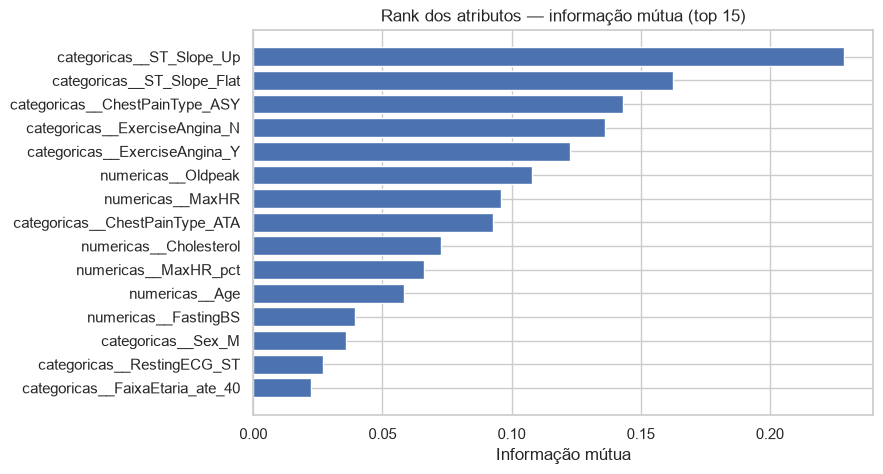

In [9]:
melhores_15 = rank_atributos.head(15).iloc[::-1]   # invertido para o maior ficar no topo do gráfico
plt.figure(figsize=(8, 5))
plt.barh(melhores_15["atributo"], melhores_15["info_mutua"])
plt.title("Rank dos atributos — informação mútua (top 15)")
plt.xlabel("Informação mútua")
salvar_figura("03_rank_atributos")
plt.show()

**Leitura:** a inclinação do segmento ST (`ST_Slope`), a dor no peito assintomática (`ChestPainType_ASY`) e a angina
no exercício (`ExerciseAngina`) lideram o ranking. As variáveis categóricas aparecem divididas em colunas
(*one-hot*), por isso um mesmo atributo original pode ocupar várias posições.

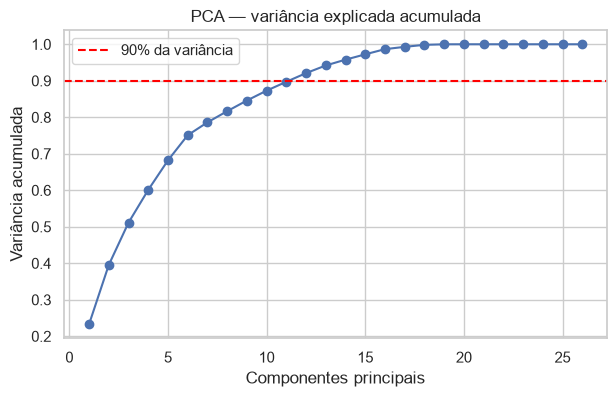

Componentes para 90% da variância: 12 de 26


In [10]:
pca = PCA().fit(atributos_transformados)
variancia_acumulada = np.cumsum(pca.explained_variance_ratio_)
componentes_para_90_por_cento = int(np.argmax(variancia_acumulada >= 0.90) + 1)

plt.figure(figsize=(7, 4))
plt.plot(range(1, len(variancia_acumulada) + 1), variancia_acumulada, marker="o")
plt.axhline(0.90, color="red", ls="--", label="90% da variância")
plt.xlabel("Componentes principais"); plt.ylabel("Variância acumulada"); plt.legend()
plt.title("PCA — variância explicada acumulada")
salvar_figura("04_pca_variancia")
plt.show()
print(f"Componentes para 90% da variância: {componentes_para_90_por_cento} de {atributos_transformados.shape[1]}")

**Leitura:** são necessários 12 dos 26 componentes para explicar 90% da variância, ou seja, os atributos têm pouca
redundância e o PCA comprimiria pouco. Por isso o Rank, que mantém os atributos originais, é a técnica usada no pipeline final.

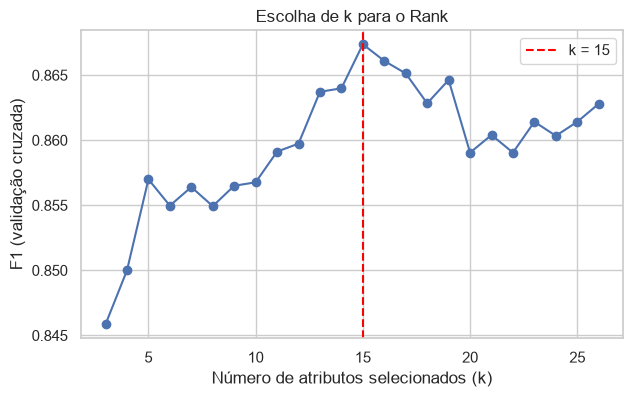

Melhor k: 15 | F1 CV: 0.8674
Atributos selecionados: ['categoricas__ST_Slope_Up', 'categoricas__ST_Slope_Flat', 'categoricas__ChestPainType_ASY', 'categoricas__ExerciseAngina_N', 'categoricas__ExerciseAngina_Y', 'numericas__Oldpeak', 'numericas__MaxHR', 'categoricas__ChestPainType_ATA', 'numericas__Cholesterol', 'numericas__MaxHR_pct', 'numericas__Age', 'numericas__FastingBS', 'categoricas__Sex_M', 'categoricas__RestingECG_ST', 'categoricas__FaixaEtaria_ate_40']


In [11]:
# Escolha do número de atributos (k) do Rank por validação cruzada, usando regressão logística e F1.
valores_de_k = list(range(3, atributos_transformados.shape[1] + 1))
f1_medio_por_k = []
for k in valores_de_k:
    resultado_cv = cross_validate(construir_pipeline(LogisticRegression(max_iter=1000), numero_atributos=k),
                                  atributos_treino, alvo_treino, cv=validacao_cruzada, scoring="f1")
    f1_medio_por_k.append(resultado_cv["test_score"].mean())

melhor_k = valores_de_k[int(np.argmax(f1_medio_por_k))]
plt.figure(figsize=(7, 4))
plt.plot(valores_de_k, f1_medio_por_k, marker="o")
plt.axvline(melhor_k, color="red", ls="--", label=f"k = {melhor_k}")
plt.xlabel("Número de atributos selecionados (k)"); plt.ylabel("F1 (validação cruzada)"); plt.legend()
plt.title("Escolha de k para o Rank")
salvar_figura("05_escolha_k")
plt.show()
print("Melhor k:", melhor_k, "| F1 CV:", round(max(f1_medio_por_k), 4))
print("Atributos selecionados:", list(rank_atributos["atributo"].head(melhor_k)))

**Leitura:** o F1 varia pouco entre os valores de k (de 84,6% a 86,7%), então a seleção por Rank não é determinante neste conjunto.
Mantemos k como um hiperparâmetro e deixamos a busca da etapa 7 comparar o valor escolhido aqui com todos os atributos.

## 6. Modelos e métricas

Três algoritmos com hiperparâmetros **padrão**, avaliados por validação cruzada estratificada (5 folds)
no conjunto de treino e, depois, no conjunto de teste. Como o contexto é médico, damos atenção especial ao
**recall** (não deixar de detectar pacientes doentes), mas o critério de escolha é o **F1**.

In [12]:
modelos_padrao = {
    "Regressão Logística": LogisticRegression(max_iter=1000, random_state=SEMENTE_ALEATORIA),
    "Random Forest": RandomForestClassifier(random_state=SEMENTE_ALEATORIA),
    "KNN": KNeighborsClassifier(),
}

linhas_validacao_cruzada = []
for nome_modelo, modelo in modelos_padrao.items():
    resultado_cv = cross_validate(construir_pipeline(modelo, numero_atributos=melhor_k),
                                  atributos_treino, alvo_treino, cv=validacao_cruzada, scoring=metricas_avaliadas)
    linhas_validacao_cruzada.append(
        {"modelo": nome_modelo, **{metrica: resultado_cv[f"test_{metrica}"].mean() for metrica in metricas_avaliadas}})

metricas_cv = pd.DataFrame(linhas_validacao_cruzada).set_index("modelo").round(4)
metricas_cv.to_csv(f"{PASTA_MODELOS}/metricas_cv_modelos_padrao.csv")
metricas_cv

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.8515,0.8620,0.8745,0.8674,0.9201
Random Forest,0.8488,0.8613,0.8696,0.8642,0.9229
KNN,0.8392,0.8509,0.8622,0.8559,0.8934


In [13]:
nome_melhor_modelo = metricas_cv["f1"].idxmax()
print("Modelo escolhido (maior F1 na validação cruzada):", nome_melhor_modelo)

linhas_teste, pipelines_treinados = [], {}
for nome_modelo, modelo in modelos_padrao.items():
    pipeline_treinado = construir_pipeline(modelo, numero_atributos=melhor_k).fit(atributos_treino, alvo_treino)
    pipelines_treinados[nome_modelo] = pipeline_treinado
    linhas_teste.append({"modelo": nome_modelo, **calcular_metricas(pipeline_treinado, atributos_teste, alvo_teste)})

metricas_teste = pd.DataFrame(linhas_teste).set_index("modelo").round(4)
metricas_teste.to_csv(f"{PASTA_MODELOS}/metricas_teste_modelos_padrao.csv")
metricas_teste

Modelo escolhido (maior F1 na validação cruzada): Regressão Logística


,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Regressão Logística,0.8967,0.9029,0.9118,0.9073,0.9365
Random Forest,0.8533,0.8641,0.8725,0.8683,0.9198
KNN,0.8370,0.8396,0.8725,0.8558,0.9014


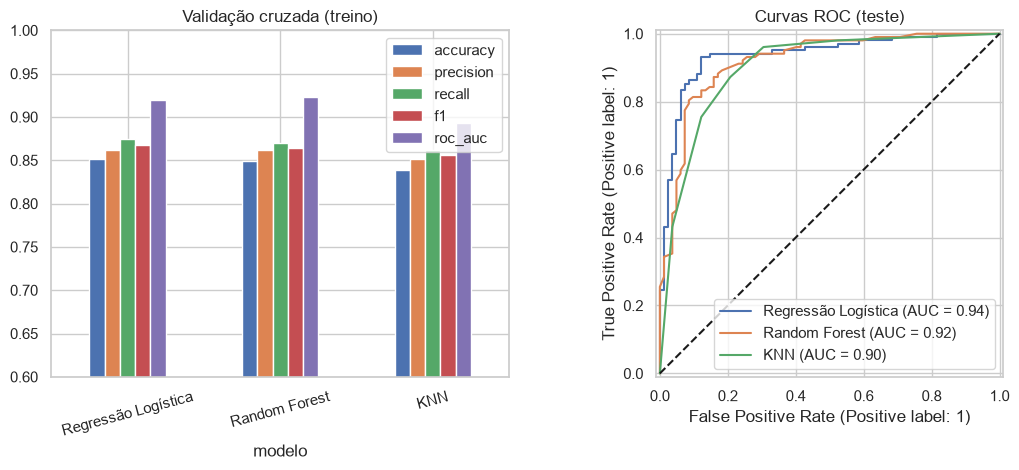

In [14]:
figura, eixos = plt.subplots(1, 2, figsize=(13, 4.5))
metricas_cv.plot.bar(ax=eixos[0], rot=15)
eixos[0].set_title("Validação cruzada (treino)"); eixos[0].set_ylim(0.6, 1)
for nome_modelo, pipeline_treinado in pipelines_treinados.items():
    RocCurveDisplay.from_estimator(pipeline_treinado, atributos_teste, alvo_teste, name=nome_modelo, ax=eixos[1])
eixos[1].plot([0, 1], [0, 1], "k--")   # linha de um classificador aleatório
eixos[1].set_title("Curvas ROC (teste)")
salvar_figura("06_comparacao_modelos")
plt.show()

**Leitura:** a Regressão Logística tem o maior F1 na validação cruzada e também o melhor desempenho no teste;
a Random Forest fica próxima na validação cruzada e o KNN fica atrás. O bom desempenho de um modelo linear simples neste
conjunto sugere que as classes se separam bem por combinações simples dos atributos.

## 7. Otimização de hiperparâmetros

Biblioteca: **scikit-learn** — `GridSearchCV` (busca em grade com validação cruzada estratificada de 5 folds,
métrica de otimização F1, `random_state = 42`). A busca é feita **somente** no treino; o teste só é usado
na comparação final.

In [15]:
# O prefixo "modelo__" e "selecao_rank__" indica a etapa do pipeline a que o hiperparâmetro pertence.
espacos_de_busca = {
    "Regressão Logística": {
        "modelo__C": [0.01, 0.1, 1, 10, 100],
        "modelo__class_weight": [None, "balanced"],
        "selecao_rank__k": [melhor_k, "all"],
    },
    "Random Forest": {
        "modelo__n_estimators": [100, 200, 300],
        "modelo__max_depth": [None, 5, 10],
        "modelo__min_samples_split": [2, 5, 10],
        "modelo__min_samples_leaf": [1, 2],
        "selecao_rank__k": [melhor_k, "all"],
    },
    "KNN": {
        "modelo__n_neighbors": [3, 5, 7, 9, 11, 15],
        "modelo__weights": ["uniform", "distance"],
        "modelo__p": [1, 2],
        "selecao_rank__k": [melhor_k, "all"],
    },
}

busca_em_grade = GridSearchCV(
    construir_pipeline(modelos_padrao[nome_melhor_modelo], numero_atributos=melhor_k),
    espacos_de_busca[nome_melhor_modelo], scoring="f1", cv=validacao_cruzada, n_jobs=-1, refit=True)
busca_em_grade.fit(atributos_treino, alvo_treino)
print("Melhores hiperparâmetros:", busca_em_grade.best_params_)
print("Melhor F1 (CV):", round(busca_em_grade.best_score_, 4))

Melhores hiperparâmetros: {'modelo__C': 0.1, 'modelo__class_weight': None, 'selecao_rank__k': 'all'}
Melhor F1 (CV): 0.8685


In [16]:
pipeline_padrao = pipelines_treinados[nome_melhor_modelo]
pipeline_otimizado = busca_em_grade.best_estimator_

comparacao_padrao_otimizado = pd.DataFrame({
    "padrão": calcular_metricas(pipeline_padrao, atributos_teste, alvo_teste),
    "otimizado": calcular_metricas(pipeline_otimizado, atributos_teste, alvo_teste),
}).T.round(4)
comparacao_padrao_otimizado.to_csv(f"{PASTA_MODELOS}/comparacao_padrao_vs_otimizado.csv")
comparacao_padrao_otimizado

,accuracy,precision,recall,f1,roc_auc
padrão,0.8967,0.9029,0.9118,0.9073,0.9365
otimizado,0.8967,0.8952,0.9216,0.9082,0.9338


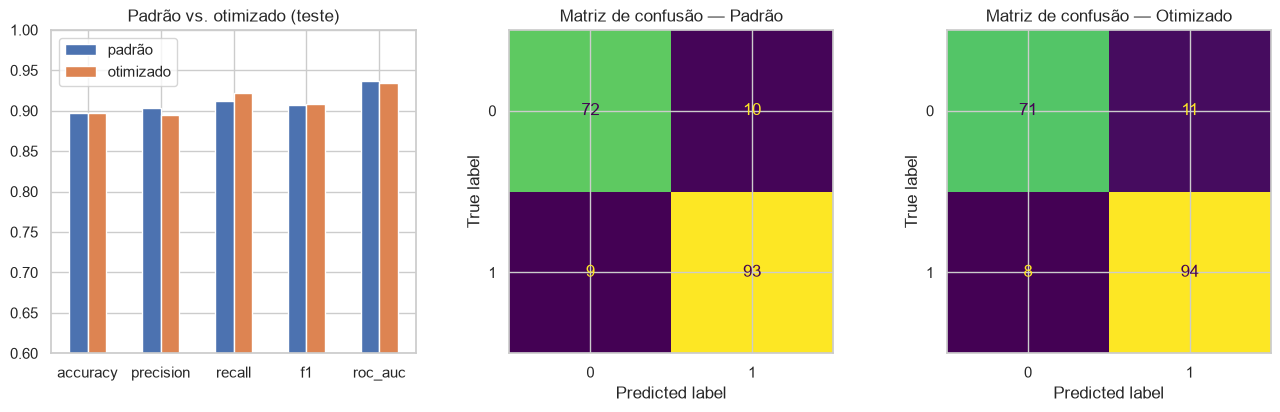

In [17]:
figura, eixos = plt.subplots(1, 3, figsize=(16, 4.2))
comparacao_padrao_otimizado.T.plot.bar(ax=eixos[0], rot=0)
eixos[0].set_ylim(0.6, 1); eixos[0].set_title("Padrão vs. otimizado (teste)")
for eixo, (titulo, pipeline_avaliado) in zip(eixos[1:], [("Padrão", pipeline_padrao), ("Otimizado", pipeline_otimizado)]):
    ConfusionMatrixDisplay.from_predictions(alvo_teste, pipeline_avaliado.predict(atributos_teste), ax=eixo, colorbar=False)
    eixo.set_title(f"Matriz de confusão — {titulo}")
salvar_figura("07_padrao_vs_otimizado")
plt.show()

**Leitura:** a otimização mantém a acurácia e troca um pouco de precisão por recall (um paciente doente a mais é detectado).
Com apenas 184 pacientes no teste, essa diferença está dentro da variação esperada: o ganho é pequeno e não deve ser
apresentado como melhora definitiva.

In [18]:
# Relatório de hiperparâmetros (insumo das seções Material e Métodos e Resultados do relatório).
hiperparametros_padrao = modelos_padrao[nome_melhor_modelo].get_params()
linhas_hiperparametros = [{
    "hiperparametro": "k (Rank, SelectKBest)",
    "espaco_testado": str(espacos_de_busca[nome_melhor_modelo]["selecao_rank__k"]),
    "valor_padrao": melhor_k,
    "valor_escolhido": busca_em_grade.best_params_["selecao_rank__k"],
}]
for nome_completo, valores_testados in espacos_de_busca[nome_melhor_modelo].items():
    if nome_completo.startswith("modelo__"):
        nome_hiperparametro = nome_completo.split("__", 1)[1]
        linhas_hiperparametros.append({
            "hiperparametro": nome_hiperparametro,
            "espaco_testado": str(valores_testados),
            "valor_padrao": str(hiperparametros_padrao.get(nome_hiperparametro)),
            "valor_escolhido": str(busca_em_grade.best_params_[nome_completo]),
        })
tabela_hiperparametros = pd.DataFrame(linhas_hiperparametros)
tabela_hiperparametros.to_csv(f"{PASTA_MODELOS}/relatorio_hiperparametros.csv", index=False)

relatorio_hiperparametros = {
    "modelo_escolhido": nome_melhor_modelo,
    "biblioteca_otimizacao": f"scikit-learn {sklearn.__version__} (GridSearchCV)",
    "validacao_cruzada": "StratifiedKFold, 5 folds, shuffle, random_state=42",
    "metrica_otimizacao": "f1",
    "melhor_f1_cv": round(float(busca_em_grade.best_score_), 4),
    "melhores_hiperparametros": {chave: (valor if isinstance(valor, (int, float, str, type(None))) else str(valor))
                                 for chave, valor in busca_em_grade.best_params_.items()},
    "metricas_teste_padrao": comparacao_padrao_otimizado.loc["padrão"].to_dict(),
    "metricas_teste_otimizado": comparacao_padrao_otimizado.loc["otimizado"].to_dict(),
    "bibliotecas": versoes_bibliotecas.set_index("biblioteca")["versao"].to_dict(),
}
with open(f"{PASTA_MODELOS}/relatorio_hiperparametros.json", "w", encoding="utf-8") as arquivo:
    json.dump(relatorio_hiperparametros, arquivo, ensure_ascii=False, indent=2)
tabela_hiperparametros

,hiperparametro,espaco_testado,valor_padrao,valor_escolhido
0,"k (Rank, SelectKBest)","[15, 'all']",15,all
1,C,"[0.01, 0.1, 1, 10, 100]",1.0,0.1
2,class_weight,"[None, 'balanced']",None,None


## 8. Exportação do modelo para produção

O pipeline completo (limpeza, novos atributos, pré-processamento, seleção Rank e modelo) é salvo em
`models/modelo.joblib` e carregado pela API (`api/main.py`), que recebe os 11 atributos originais do paciente.

In [19]:
joblib.dump(pipeline_otimizado, f"{PASTA_MODELOS}/modelo.joblib")
with open(f"{PASTA_MODELOS}/metadata.json", "w", encoding="utf-8") as arquivo:
    json.dump({"modelo": nome_melhor_modelo, "sklearn": sklearn.__version__,
               "k_rank": str(busca_em_grade.best_params_["selecao_rank__k"]),   # valor realmente usado no modelo final
               "metricas_teste": relatorio_hiperparametros["metricas_teste_otimizado"]},
              arquivo, ensure_ascii=False, indent=2)

# Teste de sanidade: recarrega o modelo salvo e prevê um paciente usando só os atributos originais.
modelo_em_producao = joblib.load(f"{PASTA_MODELOS}/modelo.joblib")
paciente_exemplo = pd.DataFrame([{
    "Age": 58, "Sex": "M", "ChestPainType": "ASY", "RestingBP": 140, "Cholesterol": 0,
    "FastingBS": 1, "RestingECG": "Normal", "MaxHR": 110, "ExerciseAngina": "Y",
    "Oldpeak": 1.5, "ST_Slope": "Flat"}])
print("Classe prevista:", int(modelo_em_producao.predict(paciente_exemplo)[0]),
      "| Probabilidade de doença:", round(float(modelo_em_producao.predict_proba(paciente_exemplo)[0, 1]), 3))

Classe prevista: 1 | Probabilidade de doença: 0.977


## 9. Conclusão

Os resultados, tabelas e figuras gerados aqui (`models/` e `relatorio/figuras/`) alimentam o relatório.
Aviso: projeto acadêmico, sem validade para uso clínico.